# What are the most demanded skills for the top 3 most popular data roles?

### Approach : 
### 1.Clean-up skill column 
### 2. Calculate the skill count based on 'job_title_short'
### 3. Calculate the skill percentage 
### 4. Plot the final readings



In [1]:

import ast
import pandas as pd
from datasets import load_dataset
import matplotlib.pyplot as plt
from adjustText import adjust_text
import seaborn as sns

dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x:ast.literal_eval(x) if pd.notna(x) else x)


In [4]:
df_IN = df[df['job_country'] == 'India']

df_IN.sample(2)

,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills
488451,Software Engineer,Platform Engineer,Anywhere,via LinkedIn,Full-time,True,India,2023-02-05 11:10:51,False,False,India,NaN,NaN,NaN,Emids,"[python, bigquery, gcp, spark, pyspark]","{'cloud': ['bigquery', 'gcp'], 'libraries': ['..."
650668,Data Scientist,Lead Applied Data Scientist,"Bengaluru, Karnataka, India",via LinkedIn,Full-time,False,India,2023-12-28 10:32:21,False,False,India,NaN,NaN,NaN,Tesco Bengaluru,"[sql, python, r, scala, hadoop]","{'libraries': ['hadoop'], 'programming': ['sql..."


In [ ]:
df_skills = df_IN.explode('job_skills')


16        powershell
16            python
16               sql
16             mysql
16        sql server
             ...    
785716            c#
785716           sql
785718           NaN
785740           aws
785740          flow
Name: job_skills, Length: 297707, dtype: str

In [15]:
df_skills_count = df_skills.groupby(['job_skills','job_title_short']).size()

df_skills_count = df_skills_count.reset_index(name = 'skill_count')
df_skills_count.sort_values(by='skill_count', ascending=False , inplace = True)

df_skills_count

,job_skills,job_title_short,skill_count
1374,sql,Data Engineer,12993
1088,python,Data Engineer,11568
1089,python,Data Scientist,9248
1327,spark,Data Engineer,7157
103,aws,Data Engineer,6993
...,...,...,...
389,esquisse,Data Scientist,1
887,node.js,Senior Data Analyst,1
753,matlab,Cloud Engineer,1
411,fastapi,Cloud Engineer,1


In [ ]:
job_titles = df_skills_count['job_title_short'].unique().tolist()

job_titles = sorted(job_titles[:3])

job_titles


['Data Analyst', 'Data Engineer', 'Data Scientist']

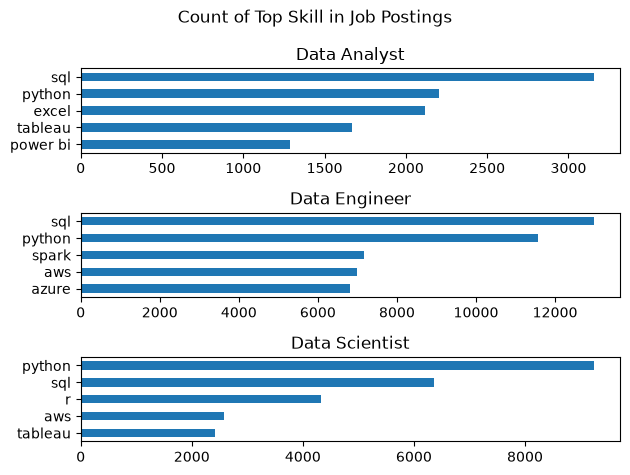

In [58]:
fig,ax=plt.subplots(3,1)

for i,job_title in enumerate(job_titles):
    df_plot = df_skills_count[(df_skills_count['job_title_short'] == job_title)].head(5)
    df_plot.plot(kind='barh',x='job_skills',y='skill_count',ax=ax[i],title=job_title,legend=False)
    ax[i].invert_yaxis()
    ax[i].set_ylabel('')

fig.suptitle('Count of Top Skill in Job Postings')

plt.tight_layout()

## % of Skill in a Job Posting


In [36]:
df_job_title_count = df_IN['job_title_short'].value_counts().reset_index(name='jobs_total')



In [68]:
df_skills_perc = pd.merge(df_skills_count,df_job_title_count, how='left',on='job_title_short')

df_skills_perc['skill_percent'] = (df_skills_perc['skill_count'] / df_skills_perc['jobs_total'])*100


df_skills_perc

,job_skills,job_title_short,skill_count,jobs_total,skill_percent
0,sql,Data Engineer,12993,19062,68.161788
1,python,Data Engineer,11568,19062,60.686182
2,python,Data Scientist,9248,13279,69.643798
3,spark,Data Engineer,7157,19062,37.545903
4,aws,Data Engineer,6993,19062,36.685552
...,...,...,...,...,...
1684,esquisse,Data Scientist,1,13279,0.007531
1685,node.js,Senior Data Analyst,1,1083,0.092336
1686,matlab,Cloud Engineer,1,351,0.284900
1687,fastapi,Cloud Engineer,1,351,0.284900


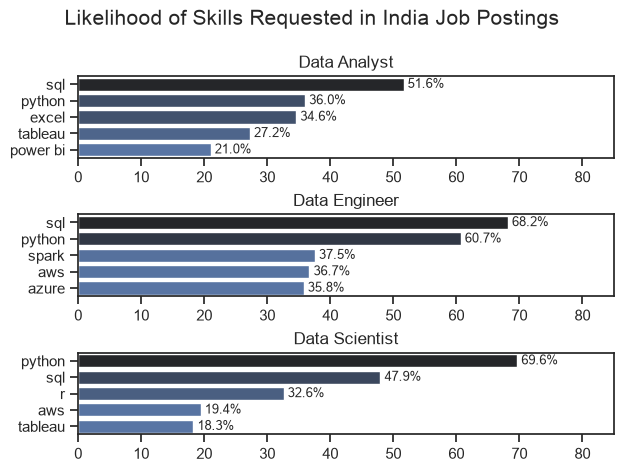

In [65]:

fig, ax = plt.subplots(len(job_titles), 1)

for i, job_title in enumerate(job_titles):
    df_plot = df_skills_perc[
        df_skills_perc['job_title_short'] == job_title
    ].head(5)

    sns.barplot(
        data=df_plot,
        x='skill_percent',
        y='job_skills',
        ax=ax[i],
        hue='skill_count',
        palette='dark:b_r'
    )

    # Add percentage labels next to each bar
    for container in ax[i].containers:
        labels = [f'{bar.get_width():.1f}%' for bar in container]
        ax[i].bar_label(container, labels=labels, padding=3, fontsize=9)

    ax[i].set_title(job_title)
    ax[i].set_ylabel('')
    ax[i].set_xlabel('')
    ax[i].get_legend().remove()
    ax[i].set_xlim(0, 85)

fig.suptitle(
    'Likelihood of Skills Requested in India Job Postings',
    fontsize=15
)

fig.tight_layout(h_pad=0.5)

plt.show()
